In [1]:
import sklearn, xgboost, imblearn
print(sklearn.__version__, xgboost.__version__, imblearn.__version__)

1.9.1 3.4.1 0.14.2


import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

1. Load and inspect data

In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

2.Clean data
Total charges is converted to numbers

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [6]:
print(df["TotalCharges"].isnull().sum())

11


Rows with missing values

In [7]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [8]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df["TotalCharges"].isnull().sum())

0


In [9]:
df = df.drop(columns=["customerID"])
df.shape

(7043, 20)

customerID is a unique label for each customer, so it carries no pattern for the model to learn, and leaving it in could make the model memorize individual rows.

3.Explore target

In [10]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


The first line gives counts and the second gives proportions. This will show how imbalanced the data is.

In [11]:
#  Churn as 0/1
#Models need numbers, so we convert “Yes” to 1 (churned) and “No” to 0 (stayed
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [12]:
print(df["Churn"].isnull().sum())

0


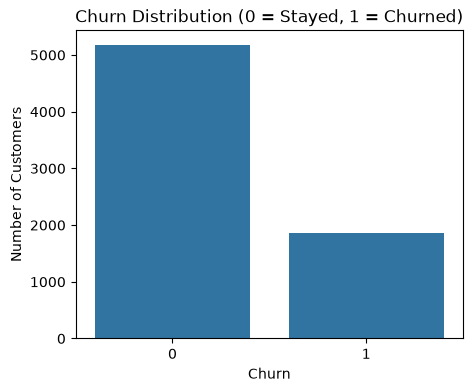

In [13]:
plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution (0 = Stayed, 1 = Churned)")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

4. Split the data

In [14]:
X = df.drop(columns=["Churn"])
y = df["Churn"]
print(X.shape, y.shape)

(7043, 19) (7043,)


x holds the input columns (19 of them) and y holds what I want to predict.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


test_size=0.2 puts 20% of the data aside for testing.
random_state=42 makes the split repeatable, so you get the same results every time you run it.
stratify=y keeps the churn ratio the same in both sets

In [16]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


5: Build the preprocessing

In [17]:
numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [col for col in X.columns if col not in numeric_cols]

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
print(len(categorical_cols))

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
15


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ]
)

handle_unknown="ignore" stops the model from crashing if the test data contains a category it never saw in training.
sparse_output=False gives a normal table, which makes it easier to read feature names later for the importance chart.
"passthrough" leaves the number columns untouched. Random Forest and XGBoost don’t need scaling, so we skip it.

In [19]:
X_train_encoded = preprocessor.fit_transform(X_train)
print(X_train_encoded.shape)

feature_names = preprocessor.get_feature_names_out()
print(feature_names[:10])

(5634, 45)
['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service']


it is fitted on the training data only The encoder learns its categories from the training set and nothing from the test set.

6.Handle the imbalance with SMOTE

In [20]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_encoded, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_res.value_counts())
print("\nShape after:", X_res.shape)

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64

Shape after: (8278, 45)


In [21]:
print(y_res.value_counts(normalize=True))

Churn
0    0.5
1    0.5
Name: proportion, dtype: float64


In [22]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(round(scale_pos_weight, 2))

2.77


classes are balanced in the demo

7.Train Random Forest with cross-validation

In [23]:
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )),
])

n_estimators=200 means 200 decision trees vote together.
n_jobs=-1 uses all your CPU cores to speed things up.


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_scores = cross_val_score(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc"
)

print("Fold scores:", rf_scores.round(4))
print("Mean ROC-AUC:", rf_scores.mean().round(4))
print("Std:", rf_scores.std().round(4))

Fold scores: [0.814  0.8031 0.8227 0.8105 0.8397]
Mean ROC-AUC: 0.818
Std: 0.0126


In [25]:
rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [26]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )),
])

learning_rate=0.05 makes each tree’s correction small, so the model learns carefully.
max_depth=4 keeps the trees shallow, which helps prevent overfitting on the SMOTE-generated rows.
eval_metric="logloss" just silences a warning and doesn’t change the results.

In [27]:
xgb_scores = cross_val_score(
    xgb_pipeline, X_train, y_train,
    cv=cv, scoring="roc_auc"
)

print("Fold scores:", xgb_scores.round(4))
print("Mean ROC-AUC:", xgb_scores.mean().round(4))
print("Std:", xgb_scores.std().round(4))

Fold scores: [0.8356 0.8316 0.842  0.8573 0.8528]
Mean ROC-AUC: 0.8438
Std: 0.0098


In [28]:
xgb_pipeline.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [29]:
print(f"Random Forest: {rf_scores.mean():.4f}")
print(f"XGBoost:       {xgb_scores.mean():.4f}")

Random Forest: 0.8180
XGBoost:       0.8438


9.Evaluate both models on the test set

In [30]:
from sklearn.metrics import roc_auc_score, classification_report

# Probability of churn (class 1), needed for ROC-AUC
rf_proba = rf_pipeline.predict_proba(X_test)[:, 1]
xgb_proba = xgb_pipeline.predict_proba(X_test)[:, 1]

# Hard 0/1 predictions, needed for the classification report
rf_pred = rf_pipeline.predict(X_test)
xgb_pred = xgb_pipeline.predict(X_test)

In [31]:
print(f"Random Forest test ROC-AUC: {roc_auc_score(y_test, rf_proba):.4f}")
print(f"XGBoost test ROC-AUC:       {roc_auc_score(y_test, xgb_proba):.4f}")

Random Forest test ROC-AUC: 0.8249
XGBoost test ROC-AUC:       0.8442


In [32]:
print("Random Forest")
print(classification_report(y_test, rf_pred, target_names=["Stayed", "Churned"]))

print("XGBoost")
print(classification_report(y_test, xgb_pred, target_names=["Stayed", "Churned"]))

Random Forest
              precision    recall  f1-score   support

      Stayed       0.83      0.88      0.85      1035
     Churned       0.59      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.78      0.77      1409

XGBoost
              precision    recall  f1-score   support

      Stayed       0.85      0.88      0.86      1035
     Churned       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.80      0.79      1409



XGBoost wins on every number in the Churned row
XGBoost catches 57% of the customers who actually churned (213 of 374), while Random Forest catches 49% (about 183). Both models are weaker at spotting churners than stayers. 

10. Plot the ROC curve

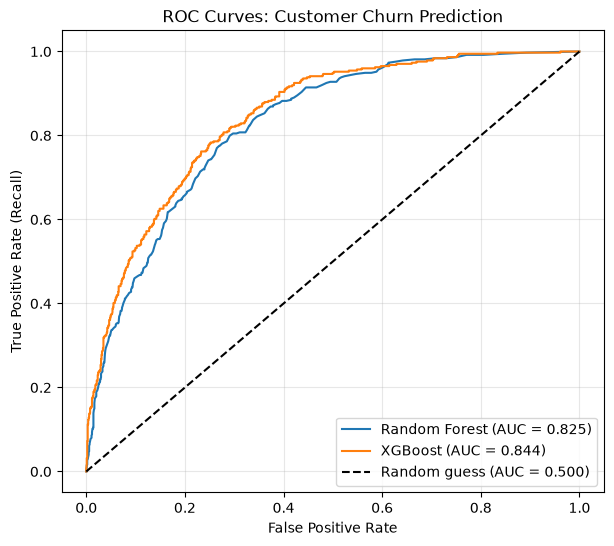

In [33]:
from sklearn.metrics import roc_curve

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)

auc_rf = roc_auc_score(y_test, rf_proba)
auc_xgb = roc_auc_score(y_test, xgb_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.3f})")
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves: Customer Churn Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [34]:
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

11.Plot the confusion matrix (XGBoost)

In [35]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, xgb_pred)
print(cm)

[[909 126]
 [160 214]]


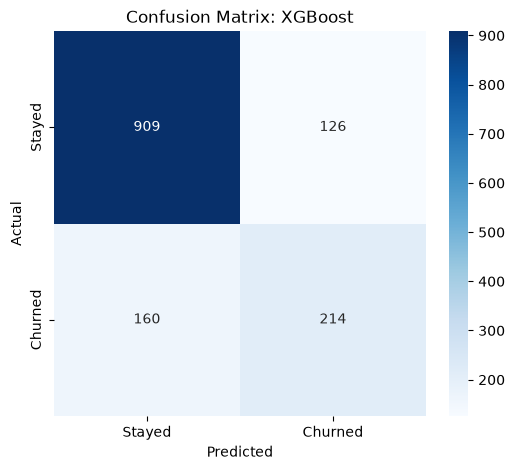

In [36]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: XGBoost")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

12. Features and names

In [37]:
feature_names = xgb_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = xgb_pipeline.named_steps["model"].feature_importances_

print(len(feature_names), len(importances))

45 45


In [38]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# remove the "cat__" and "num__" prefixes for readability
importance_df["feature"] = (
    importance_df["feature"]
    .str.replace("cat__", "", regex=False)
    .str.replace("num__", "", regex=False)
)

top10 = importance_df.sort_values("importance", ascending=False).head(10)
print(top10)

                           feature  importance
32         Contract_Month-to-month    0.342342
23                  TechSupport_No    0.091401
14               OnlineSecurity_No    0.089387
39  PaymentMethod_Electronic check    0.065297
17                 OnlineBackup_No    0.051326
12     InternetService_Fiber optic    0.039412
35             PaperlessBilling_No    0.027530
31             StreamingMovies_Yes    0.024854
4                    Dependents_No    0.023978
25                 TechSupport_Yes    0.020630


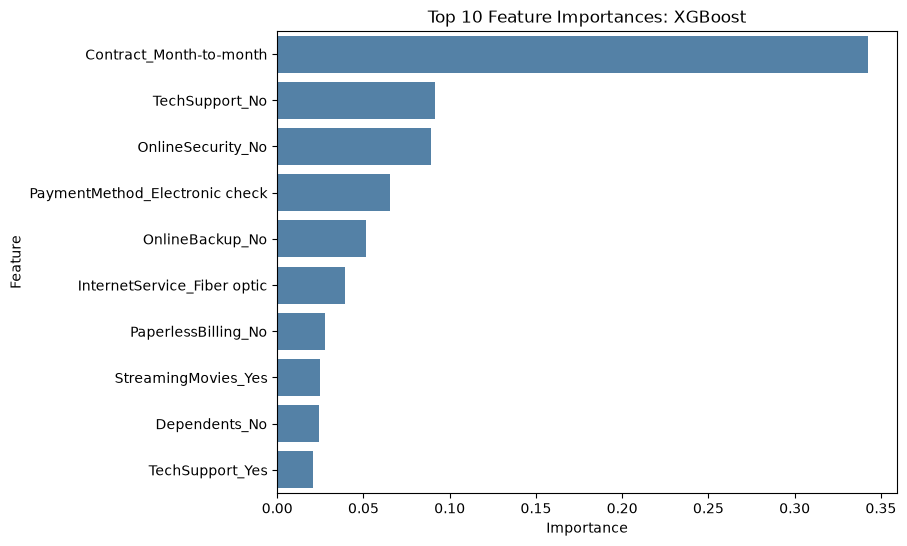

In [39]:
plt.figure(figsize=(8, 6))
sns.barplot(data=top10, x="importance", y="feature", color="steelblue")
plt.title("Top 10 Feature Importances: XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance shows what the model relied on, not what is associated with churn. A feature like Contract_Month-to-month ranking high means the model found it useful for prediction, which fits a story where customers without long contracts leave more easily.

Conclusion

a. Two models were trained on the Telco churn data with SMOTE applied inside the cross-validation pipeline (training folds only): Random Forest and XGBoost.
b.  XGBoost performed best: 5-fold CV ROC-AUC of 0.844 and test ROC-AUC of 0.844, above the 0.80 target. Random Forest scored 0.818 (CV) and 0.825 (test).
c. At the default 0.5 threshold, XGBoost caught 214 of 374 churners (recall 0.57, precision 0.63).
d. The strongest features were month-to-month contracts, no tech support, no online security, and electronic check payment. These are associations, not proven causes.
